In [1]:
import mysql.connector


In [2]:
!pip install mysql-connector-python 


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
con=mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="food_delivery")



In [4]:
print("connection established successfully")


connection established successfully


In [5]:
cursor=con.cursor()
query="select *FROM orders"

In [6]:
cursor.execute(query)


In [7]:
results=cursor.fetchall()
for row in results:
    print(row)
    

(1, 1, 101, datetime.date(2026, 1, 1), Decimal('450.00'), 31, 'UPI', 'Delivered')
(2, 2, 102, datetime.date(2026, 1, 1), Decimal('620.00'), 40, 'Card', 'Delivered')
(3, 3, 103, datetime.date(2026, 1, 2), Decimal('380.00'), 34, 'Cash', 'Delivered')
(4, 4, 104, datetime.date(2026, 1, 2), Decimal('520.00'), 29, 'UPI', 'Delivered')
(5, 5, 105, datetime.date(2026, 1, 3), Decimal('700.00'), 43, 'Card', 'Cancelled')
(6, 6, 106, datetime.date(2026, 1, 3), Decimal('430.00'), 37, 'UPI', 'Delivered')
(7, 7, 107, datetime.date(2026, 1, 4), Decimal('350.00'), 27, 'Cash', 'Delivered')
(8, 8, 108, datetime.date(2026, 1, 4), Decimal('680.00'), 35, 'UPI', 'Delivered')
(9, 9, 109, datetime.date(2026, 1, 5), Decimal('290.00'), 24, 'Card', 'Delivered')
(10, 10, 110, datetime.date(2026, 1, 5), Decimal('560.00'), 45, 'UPI', 'Delivered')
(11, 11, 111, datetime.date(2026, 1, 6), Decimal('470.00'), 38, 'Cash', 'Delivered')
(12, 12, 112, datetime.date(2026, 1, 6), Decimal('610.00'), 36, 'Card', 'Delivered')
(13

In [8]:
import pandas as pd

In [9]:
query="select * from orders"

In [10]:
df=pd.read_sql(query,con)

C:\Users\acer\AppData\Local\Temp\ipykernel_18068\2212408280.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql(query,con)


In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [34]:
import mysql.connector

con = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="food_delivery"
)

print("Database connected successfully!")




Database connected successfully!


In [36]:
import pandas as pd

restaurants = pd.read_sql(
    "SELECT * FROM Restaurants",
    con
)

orders = pd.read_sql(
    "SELECT * FROM Orders",
    con
)

print("Restaurants:", restaurants.shape)
print("Orders:", orders.shape)


Restaurants: (100, 7)
Orders: (100, 8)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\4080379310.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  restaurants = pd.read_sql(
C:\Users\acer\AppData\Local\Temp\ipykernel_18068\4080379310.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  orders = pd.read_sql(


In [37]:
restaurants.head()


,restaurant_id,restaurant_name,cuisine,city,rating,avg_delivery_time,total_orders
0,1,Spice Hub,Indian,Chennai,4.5,32,245
1,2,Pizza Palace,Italian,Mumbai,4.2,38,310
2,3,Burger Point,American,Bangalore,4.0,35,280
3,4,Curry House,Indian,Hyderabad,4.4,30,225
4,5,Dragon Bowl,Chinese,Chennai,4.1,40,198


In [38]:
orders.head()


,order_id,restaurant_id,customer_id,order_date,order_amount,delivery_time,payment_method,order_status
0,1,1,101,2026-01-01,450.0,31,UPI,Delivered
1,2,2,102,2026-01-01,620.0,40,Card,Delivered
2,3,3,103,2026-01-02,380.0,34,Cash,Delivered
3,4,4,104,2026-01-02,520.0,29,UPI,Delivered
4,5,5,105,2026-01-03,700.0,43,Card,Cancelled


In [39]:
print("Total Restaurants:", restaurants["restaurant_id"].nunique())
print("Total Orders:", orders["order_id"].nunique())
print("Total Customers:", orders["customer_id"].nunique())
print("Average Order Amount:", round(orders["order_amount"].mean(), 2))
print("Average Delivery Time:", round(orders["delivery_time"].mean(), 2), "minutes")
print("Average Restaurant Rating:", round(restaurants["rating"].mean(), 2))


Total Restaurants: 100
Total Orders: 100
Total Customers: 100
Average Order Amount: 496.2
Average Delivery Time: 34.11 minutes
Average Restaurant Rating: 4.37


In [40]:
print(orders["order_status"].value_counts())


order_status
Delivered    89
Cancelled    11
Name: count, dtype: int64


In [41]:
cancelled = (orders["order_status"] == "Cancelled").sum()

cancellation_rate = (cancelled / len(orders)) * 100

print("Cancellation Rate:",
      round(cancellation_rate, 2), "%")


Cancellation Rate: 11.0 %


In [42]:
cuisine_analysis = restaurants["cuisine"].value_counts()

print(cuisine_analysis)


cuisine
Chinese          12
Indian           10
Italian          10
South Indian     10
Biryani           8
American          6
Mexican           6
Vegetarian        6
Desserts          6
Cafe              6
Grill             4
Mughlai           4
Street Food       4
North Indian      4
Multi-Cuisine     2
Healthy           2
Name: count, dtype: int64


In [43]:
city_analysis = (
    restaurants.groupby("city")
    .agg(
        restaurants=("restaurant_id", "count"),
        avg_rating=("rating", "mean"),
        avg_delivery_time=("avg_delivery_time", "mean")
    )
    .round(2)
)

print(city_analysis)


           restaurants  avg_rating  avg_delivery_time
city                                                 
Bangalore           16        4.39              32.81
Chennai             23        4.43              30.13
Delhi               19        4.37              33.63
Hyderabad           13        4.38              34.31
Kolkata              1        4.00              41.00
Mumbai              16        4.29              34.69
Pune                12        4.36              33.42


In [44]:
df = pd.merge(
    orders,
    restaurants,
    on="restaurant_id",
    how="inner"
)


In [45]:
restaurant_analysis = (
    df.groupby(["restaurant_name", "cuisine"])
    .agg(
        orders=("order_id", "count"),
        revenue=("order_amount", "sum"),
        avg_order_amount=("order_amount", "mean"),
        avg_delivery_time=("delivery_time", "mean"),
        rating=("rating", "first")
    )
    .sort_values("revenue", ascending=False)
    .round(2)
)

display(restaurant_analysis.head(10))


,,orders,revenue,avg_order_amount,avg_delivery_time,rating
restaurant_name,cuisine,,,,,
Royal Biryani,Biryani,2,1460.0,730.0,33.5,4.7
Dragon Bowl,Chinese,2,1200.0,600.0,42.5,4.1
Wok Express,Chinese,2,970.0,485.0,40.0,4.1
Kebab Point,Mughlai,1,760.0,760.0,35.0,4.5
Biryani World,Biryani,1,750.0,750.0,35.0,4.7
Kebab Kingdom,Mughlai,1,750.0,750.0,34.0,4.5
Green Garden,Vegetarian,2,750.0,375.0,28.0,4.6
Biryani Junction,Biryani,1,740.0,740.0,34.0,4.7
Biryani Palace,Biryani,1,720.0,720.0,36.0,4.6


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\1525664652.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


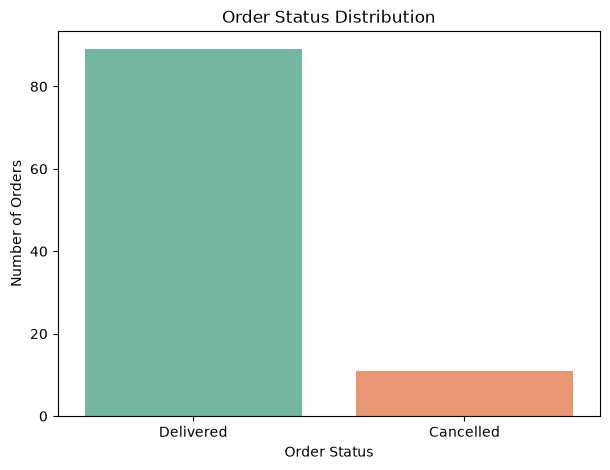

In [46]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=orders,
    x="order_status",
    palette="Set2"
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.show()


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\138952548.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


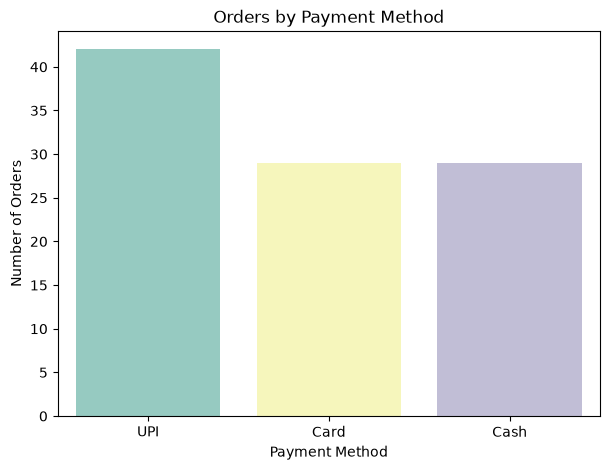

In [48]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=orders,
    x="payment_method",
    palette="Set3"
)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.show()


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\356968807.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


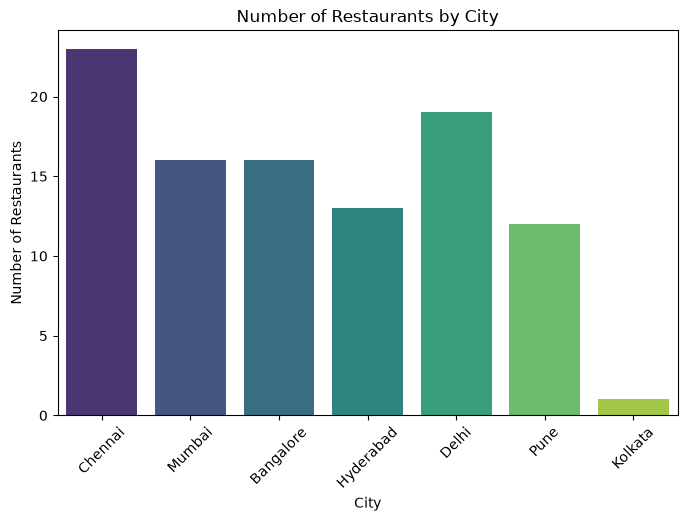

In [49]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=restaurants,
    x="city",
    palette="viridis"
)

plt.title("Number of Restaurants by City")
plt.xlabel("City")
plt.ylabel("Number of Restaurants")

plt.xticks(rotation=45)

plt.show()


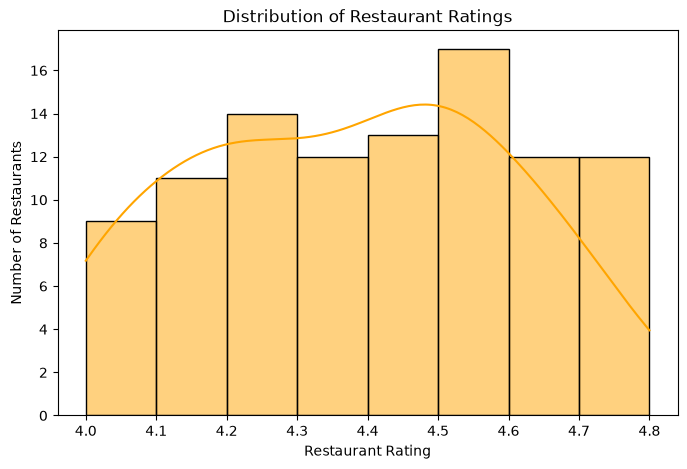

In [50]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=restaurants,
    x="rating",
    bins=8,
    kde=True,
    color="orange"
)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Restaurant Rating")
plt.ylabel("Number of Restaurants")

plt.show()


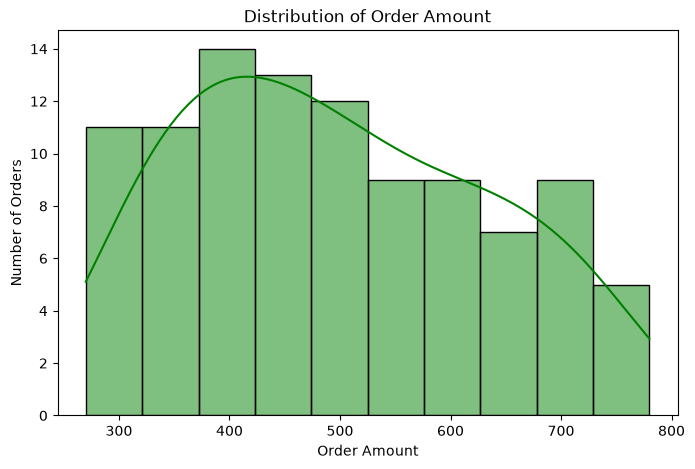

In [51]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=orders,
    x="order_amount",
    bins=10,
    kde=True,
    color="green"
)

plt.title("Distribution of Order Amount")
plt.xlabel("Order Amount")
plt.ylabel("Number of Orders")

plt.show()


In [53]:
query6 = """
SELECT 
    r.city,
    SUM(o.order_amount) AS total_revenue
FROM Orders o
JOIN Restaurants r
    ON o.restaurant_id = r.restaurant_id
WHERE o.order_status = 'Delivered'
GROUP BY r.city
ORDER BY total_revenue DESC;
"""

city_revenue = pd.read_sql(query6, con)

display(city_revenue)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\4116025259.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  city_revenue = pd.read_sql(query6, con)


,city,total_revenue
0,Delhi,10370.0
1,Chennai,8780.0
2,Hyderabad,6400.0
3,Bangalore,6360.0
4,Mumbai,6200.0
5,Pune,5490.0


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\2256383554.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


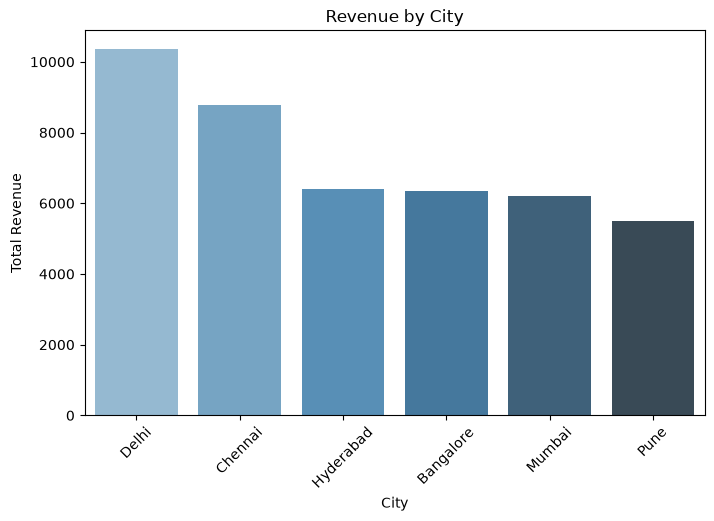

In [54]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=city_revenue,
    x="city",
    y="total_revenue",
    palette="Blues_d"
)

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.show()


In [56]:
query7 = """
SELECT
    r.cuisine,
    AVG(o.order_amount) AS avg_order_amount
FROM Orders o
JOIN Restaurants r
    ON o.restaurant_id = r.restaurant_id
WHERE o.order_status = 'Delivered'
GROUP BY r.cuisine
ORDER BY avg_order_amount DESC;
"""

cuisine_order = pd.read_sql(query7, con)

display(cuisine_order)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\360276310.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  cuisine_order = pd.read_sql(query7, con)


,cuisine,avg_order_amount
0,Biryani,723.750000
1,Mughlai,722.500000
2,North Indian,652.500000
3,Italian,616.250000
4,Grill,582.500000
5,Indian,528.000000
6,Chinese,510.000000
7,Multi-Cuisine,470.000000
8,Mexican,436.000000
9,American,435.000000


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\3653837289.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


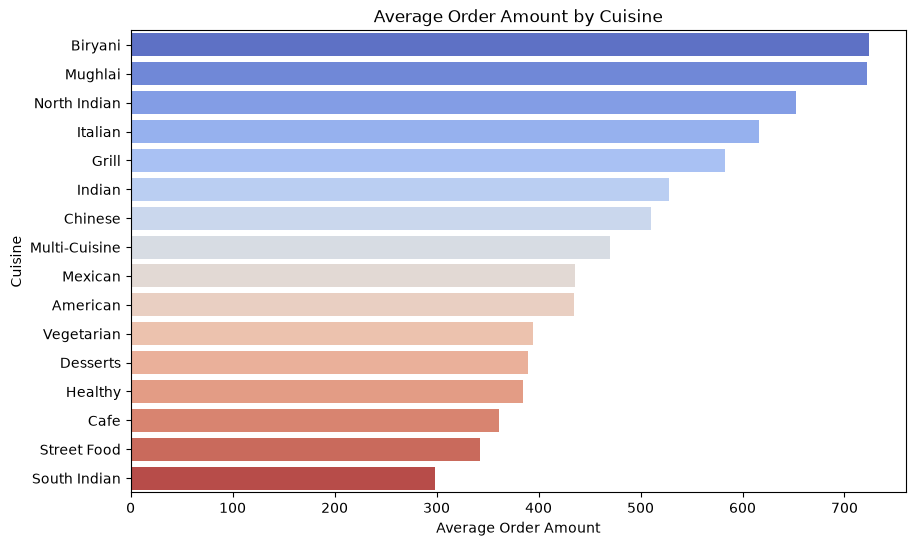

In [57]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=cuisine_order,
    x="avg_order_amount",
    y="cuisine",
    palette="coolwarm"
)

plt.title("Average Order Amount by Cuisine")
plt.xlabel("Average Order Amount")
plt.ylabel("Cuisine")

plt.show()


In [59]:
query8 = """
SELECT
    r.restaurant_name,
    SUM(o.order_amount) AS total_revenue
FROM Orders o
JOIN Restaurants r
    ON o.restaurant_id = r.restaurant_id
WHERE o.order_status = 'Delivered'
GROUP BY r.restaurant_id, r.restaurant_name
ORDER BY total_revenue DESC
LIMIT 10;
"""

top_restaurants = pd.read_sql(query8, con)

display(top_restaurants)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\1481901647.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_restaurants = pd.read_sql(query8, con)


,restaurant_name,total_revenue
0,Royal Biryani,780.0
1,Kebab Point,760.0
2,Biryani World,750.0
3,Kebab Kingdom,750.0
4,Biryani Junction,740.0
5,Biryani House,720.0
6,Biryani Palace,720.0
7,Biryani Express,710.0
8,Biryani Blues,690.0
9,Kebab Express,690.0


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\2937601679.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


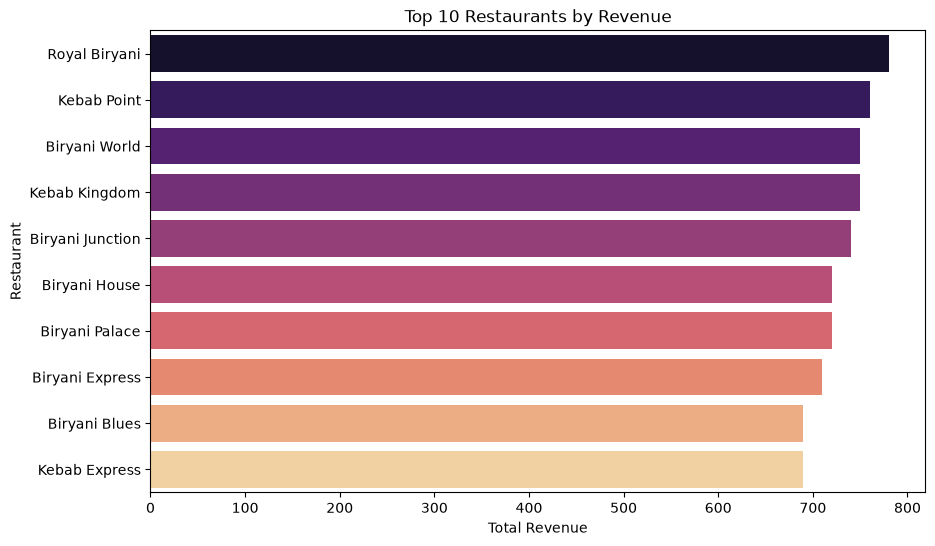

In [60]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_restaurants,
    x="total_revenue",
    y="restaurant_name",
    palette="magma"
)

plt.title("Top 10 Restaurants by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Restaurant")

plt.show()


In [62]:
query9 = """
SELECT
    restaurant_name,
    rating
FROM Restaurants
WHERE rating > (
    SELECT AVG(rating)
    FROM Restaurants
)
ORDER BY rating DESC;
"""

above_avg_rating = pd.read_sql(query9, con)

display(above_avg_rating)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\2065207798.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  above_avg_rating = pd.read_sql(query9, con)


,restaurant_name,rating
0,Dosa Delight,4.8
1,Royal Biryani,4.8
2,Dosa Palace,4.8
3,Biryani Junction,4.7
4,Royal Biryani,4.7
5,South Indian Cafe,4.7
6,Dessert Palace,4.7
7,Dessert World,4.7
8,Sweet Palace,4.7
9,Dessert Cafe,4.7


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\4170276283.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


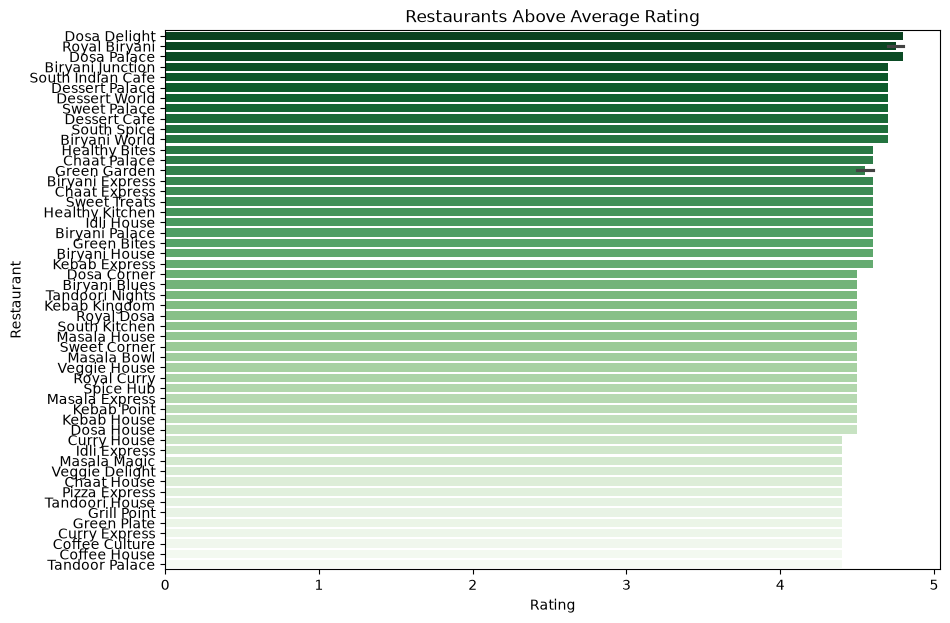

In [63]:
plt.figure(figsize=(10,7))

sns.barplot(
    data=above_avg_rating,
    x="rating",
    y="restaurant_name",
    palette="Greens_r"
)

plt.title("Restaurants Above Average Rating")
plt.xlabel("Rating")
plt.ylabel("Restaurant")

plt.show()


In [65]:
query10 = """
SELECT
    restaurant_name,
    total_orders
FROM Restaurants
WHERE total_orders > (
    SELECT AVG(total_orders)
    FROM Restaurants
)
ORDER BY total_orders DESC;
"""

above_avg_orders = pd.read_sql(query10, con)

display(above_avg_orders)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\96802888.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  above_avg_orders = pd.read_sql(query10, con)


,restaurant_name,total_orders
0,Dosa Delight,450
1,Dosa Palace,440
2,South Kitchen,425
3,South Indian Cafe,415
4,Dosa Corner,410
5,South Spice,400
6,Royal Biryani,400
7,Idli House,395
8,Biryani Junction,390
9,Dosa House,385


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\150985076.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


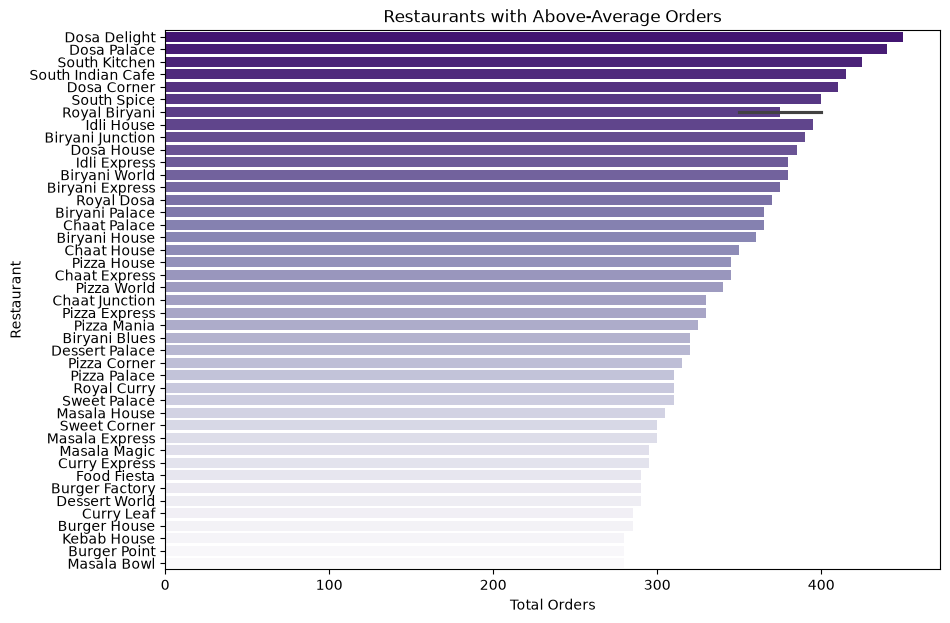

In [66]:
plt.figure(figsize=(10,7))

sns.barplot(
    data=above_avg_orders,
    x="total_orders",
    y="restaurant_name",
    palette="Purples_r"
)

plt.title("Restaurants with Above-Average Orders")
plt.xlabel("Total Orders")
plt.ylabel("Restaurant")

plt.show()


In [68]:
query_daily = """
SELECT
    order_date,
    SUM(order_amount) AS daily_revenue
FROM Orders
WHERE order_status = 'Delivered'
GROUP BY order_date
ORDER BY order_date;
"""

daily_revenue = pd.read_sql(query_daily, con)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\4060024299.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  daily_revenue = pd.read_sql(query_daily, con)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\2260909663.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


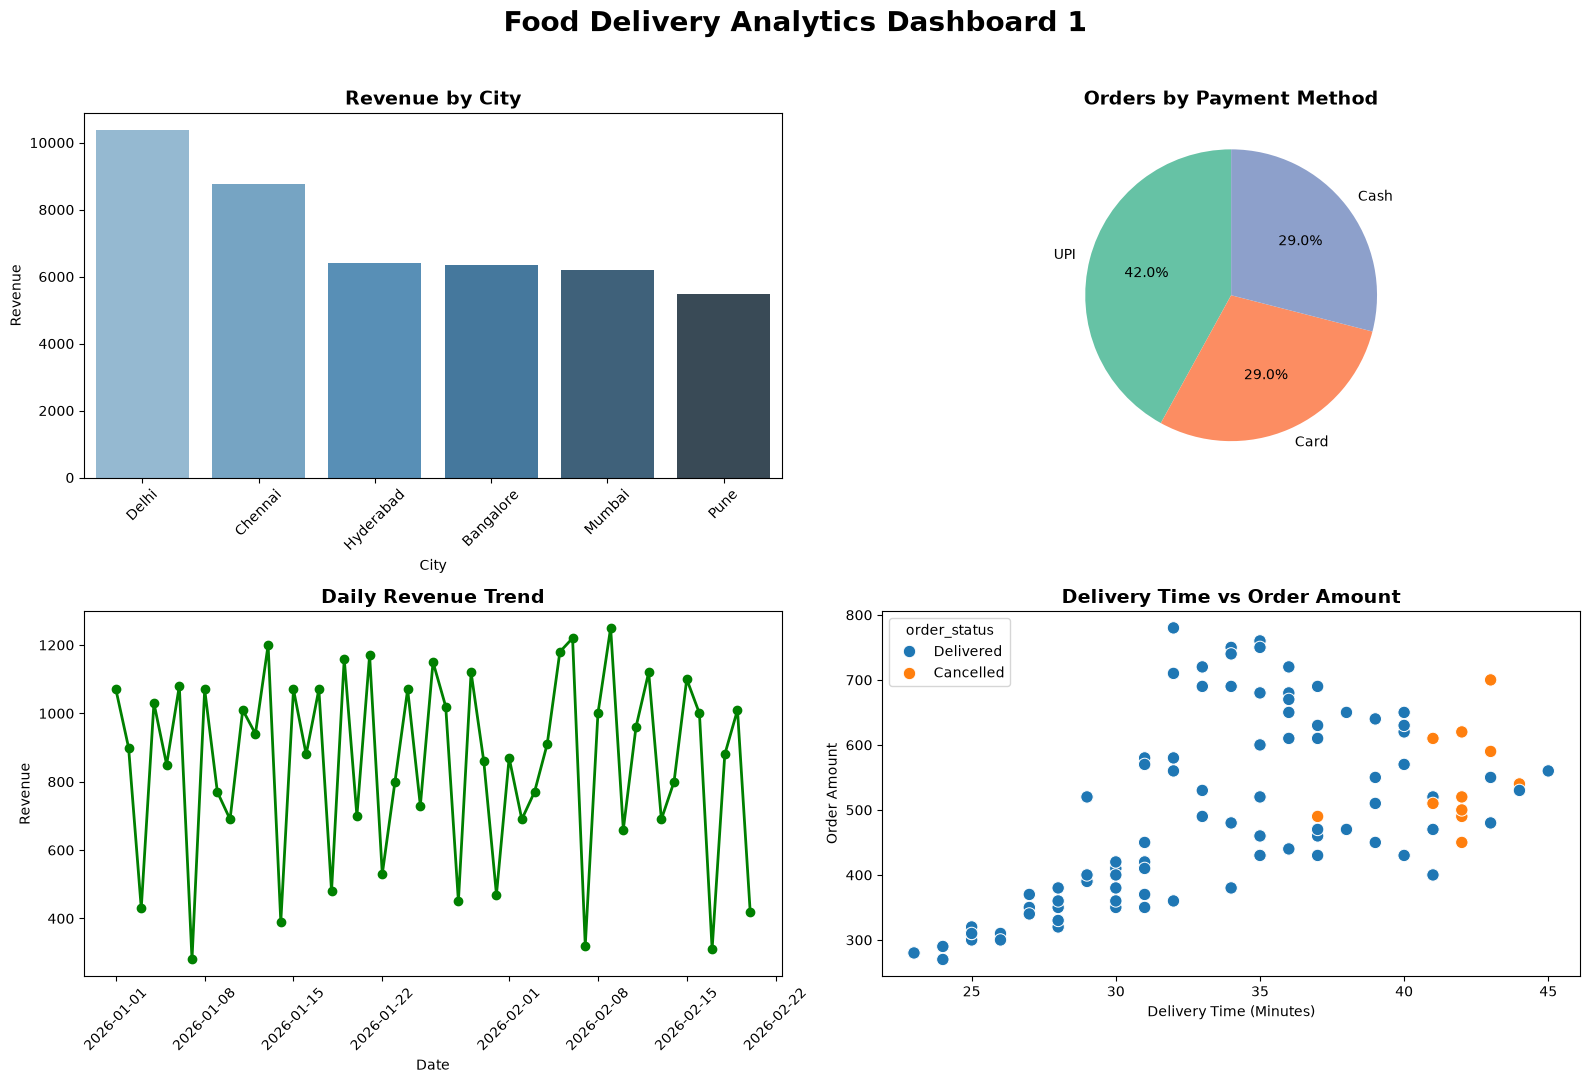

In [69]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# --------------------------------
# Chart 1: City-wise Revenue
# --------------------------------

sns.barplot(
    data=city_revenue,
    x="city",
    y="total_revenue",
    ax=axes[0, 0],
    palette="Blues_d"
)

axes[0, 0].set_title(
    "Revenue by City",
    fontsize=14,
    fontweight="bold"
)

axes[0, 0].set_xlabel("City")
axes[0, 0].set_ylabel("Revenue")

axes[0, 0].tick_params(axis="x", rotation=45)


# --------------------------------
# Chart 2: Payment Method
# --------------------------------

payment_counts = orders["payment_method"].value_counts()

axes[0, 1].pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#66c2a5", "#fc8d62", "#8da0cb"]
)

axes[0, 1].set_title(
    "Orders by Payment Method",
    fontsize=14,
    fontweight="bold"
)


# --------------------------------
# Chart 3: Daily Revenue
# --------------------------------

axes[1, 0].plot(
    daily_revenue["order_date"],
    daily_revenue["daily_revenue"],
    marker="o",
    color="green",
    linewidth=2
)

axes[1, 0].set_title(
    "Daily Revenue Trend",
    fontsize=14,
    fontweight="bold"
)

axes[1, 0].set_xlabel("Date")
axes[1, 0].set_ylabel("Revenue")

axes[1, 0].tick_params(
    axis="x",
    rotation=45
)


# --------------------------------
# Chart 4: Delivery Time vs Order Amount
# --------------------------------

sns.scatterplot(
    data=orders,
    x="delivery_time",
    y="order_amount",
    hue="order_status",
    ax=axes[1, 1],
    s=80
)

axes[1, 1].set_title(
    "Delivery Time vs Order Amount",
    fontsize=14,
    fontweight="bold"
)

axes[1, 1].set_xlabel("Delivery Time (Minutes)")
axes[1, 1].set_ylabel("Order Amount")


# --------------------------------
# Dashboard Title
# --------------------------------

fig.suptitle(
    "Food Delivery Analytics Dashboard 1",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()


In [70]:
# Top restaurants by orders
query_top_orders = """
SELECT
    r.restaurant_name,
    r.total_orders
FROM Restaurants r
ORDER BY r.total_orders DESC
LIMIT 10;
"""

top_orders = pd.read_sql(query_top_orders, con)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\4107756301.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_orders = pd.read_sql(query_top_orders, con)


In [71]:
city_cuisine = pd.crosstab(
    restaurants["city"],
    restaurants["cuisine"]
)


In [72]:
daily_revenue["cumulative_revenue"] = (
    daily_revenue["daily_revenue"].cumsum()
)


C:\Users\acer\AppData\Local\Temp\ipykernel_18068\1115284871.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\acer\AppData\Local\Temp\ipykernel_18068\1115284871.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


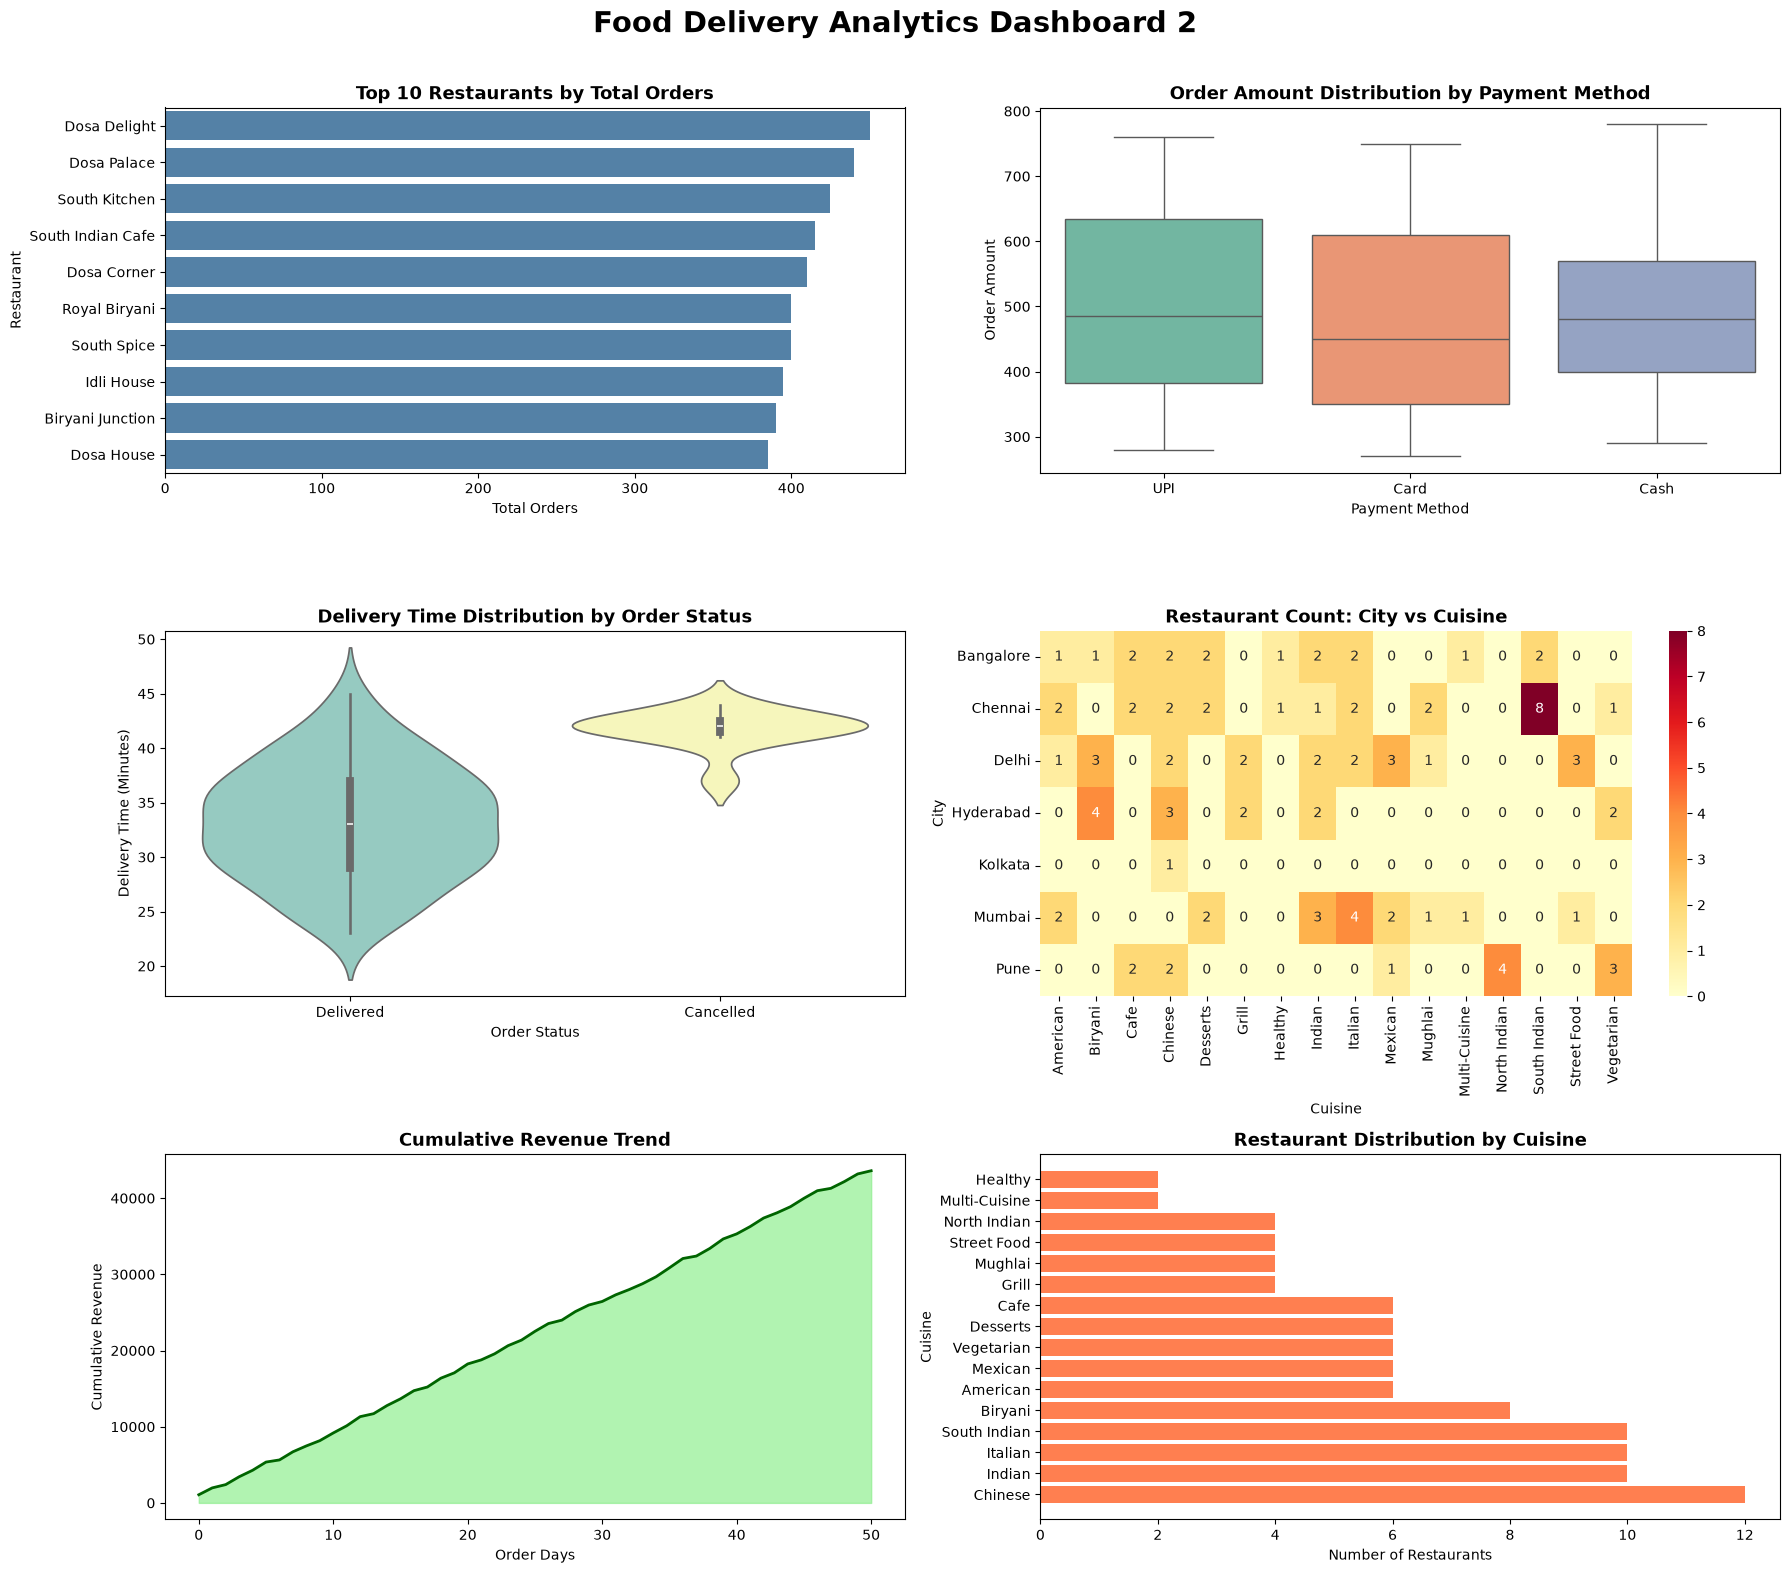

In [73]:
fig, axes = plt.subplots(3, 2, figsize=(18, 16))

# ==========================================
# 1. Top 10 Restaurants by Orders
# ==========================================

sns.barplot(
    data=top_orders,
    x="total_orders",
    y="restaurant_name",
    ax=axes[0, 0],
    color="steelblue"
)

axes[0, 0].set_title(
    "Top 10 Restaurants by Total Orders",
    fontsize=13,
    fontweight="bold"
)

axes[0, 0].set_xlabel("Total Orders")
axes[0, 0].set_ylabel("Restaurant")


# ==========================================
# 2. Order Amount by Payment Method
# ==========================================

sns.boxplot(
    data=orders,
    x="payment_method",
    y="order_amount",
    ax=axes[0, 1],
    palette="Set2"
)

axes[0, 1].set_title(
    "Order Amount Distribution by Payment Method",
    fontsize=13,
    fontweight="bold"
)

axes[0, 1].set_xlabel("Payment Method")
axes[0, 1].set_ylabel("Order Amount")


# ==========================================
# 3. Delivery Time by Order Status
# ==========================================

sns.violinplot(
    data=orders,
    x="order_status",
    y="delivery_time",
    ax=axes[1, 0],
    palette="Set3"
)

axes[1, 0].set_title(
    "Delivery Time Distribution by Order Status",
    fontsize=13,
    fontweight="bold"
)

axes[1, 0].set_xlabel("Order Status")
axes[1, 0].set_ylabel("Delivery Time (Minutes)")


# ==========================================
# 4. City vs Cuisine Heatmap
# ==========================================

sns.heatmap(
    city_cuisine,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Restaurant Count: City vs Cuisine",
    fontsize=13,
    fontweight="bold"
)

axes[1, 1].set_xlabel("Cuisine")
axes[1, 1].set_ylabel("City")


# ==========================================
# 5. Cumulative Revenue
# ==========================================

axes[2, 0].fill_between(
    range(len(daily_revenue)),
    daily_revenue["cumulative_revenue"],
    color="lightgreen",
    alpha=0.7
)

axes[2, 0].plot(
    range(len(daily_revenue)),
    daily_revenue["cumulative_revenue"],
    color="darkgreen",
    linewidth=2
)

axes[2, 0].set_title(
    "Cumulative Revenue Trend",
    fontsize=13,
    fontweight="bold"
)

axes[2, 0].set_xlabel("Order Days")
axes[2, 0].set_ylabel("Cumulative Revenue")


# ==========================================
# 6. Cuisine Distribution
# ==========================================

cuisine_counts = restaurants["cuisine"].value_counts()

axes[2, 1].barh(
    cuisine_counts.index,
    cuisine_counts.values,
    color="coral"
)

axes[2, 1].set_title(
    "Restaurant Distribution by Cuisine",
    fontsize=13,
    fontweight="bold"
)

axes[2, 1].set_xlabel("Number of Restaurants")
axes[2, 1].set_ylabel("Cuisine")


# ==========================================
# Dashboard Title
# ==========================================

fig.suptitle(
    "Food Delivery Analytics Dashboard 2",
    fontsize=21,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()
